In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier

PROJECT_ROOT = Path(
    r"C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING"
)

DATA = PROJECT_ROOT / "all_datasets"

required_files = [
    "credit_card_fraud_dataset.csv",
    "breast_cancer_dataset.csv",
]

for filename in required_files:
    path = DATA / filename
    print(filename, "->", "FOUND" if path.exists() else "MISSING")

missing = [
    filename for filename in required_files
    if not (DATA / filename).exists()
]

if missing:
    raise FileNotFoundError(
        f"These files must be inside {DATA}: {missing}"
    )

credit_card_fraud_dataset.csv -> FOUND
breast_cancer_dataset.csv -> FOUND


In [2]:
fraud = pd.read_csv(DATA / "credit_card_fraud_dataset.csv")

display(fraud.head())
print("Dataset shape:", fraud.shape)

feature_cols = [
    "amount",
    "transaction_hour",
    "foreign_transaction",
    "location_mismatch",
    "device_trust_score",
    "velocity_last_24h",
    "cardholder_age",
]

X = fraud[feature_cols]
y = fraud["is_fraud"]

print("\nMissing feature values:")
print(X.isna().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print("\nTraining transactions:", len(X_train))
print("Test transactions:", len(X_test))
print("Test fraud cases:", int(y_test.sum()))

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


Dataset shape: (10000, 10)

Missing feature values:
amount                 0
transaction_hour       0
foreign_transaction    0
location_mismatch      0
device_trust_score     0
velocity_last_24h      0
cardholder_age         0
dtype: int64

Training transactions: 7000
Test transactions: 3000
Test fraud cases: 45


In [3]:
forest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42,
    n_jobs=-1,
)

# Unsupervised fitting: no fraud labels are passed.
forest.fit(X_train)

# Reverse the sign so higher values mean more unusual.
anomaly_score = -forest.decision_function(X_test)

prevalence = y_test.mean()
roc_auc = roc_auc_score(y_test, anomaly_score)
ap = average_precision_score(y_test, anomaly_score)

fraud_metrics = pd.DataFrame({
    "Metric": [
        "Test fraud prevalence",
        "ROC AUC",
        "Average precision",
        "Average precision / prevalence",
    ],
    "Value": [
        prevalence,
        roc_auc,
        ap,
        ap / prevalence,
    ],
})

display(fraud_metrics.round(4))

,Metric,Value
0,Test fraud prevalence,0.0150
1,ROC AUC,0.9518
2,Average precision,0.2249
3,Average precision / prevalence,14.9939


In [4]:
ranked = X_test.copy()
ranked["fraud_label"] = y_test.to_numpy()
ranked["anomaly_score"] = anomaly_score

ranked = ranked.sort_values(
    "anomaly_score",
    ascending=False,
)

budget_rows = []

for budget in [50, 100, 300]:
    reviewed = ranked.head(budget)
    found = int(reviewed["fraud_label"].sum())
    precision = reviewed["fraud_label"].mean()

    budget_rows.append({
        "Review budget": len(reviewed),
        "Fraud found": found,
        "Non-fraud alerts": len(reviewed) - found,
        "Precision": precision,
        "Recall": found / int(y_test.sum()),
        "Precision / prevalence": precision / prevalence,
    })

budget_results = pd.DataFrame(budget_rows)

display(budget_results.round(4))

print("\nTop ten ranked transactions:")
display(
    ranked[["fraud_label", "anomaly_score", "amount"]].head(10)
)

,Review budget,Fraud found,Non-fraud alerts,Precision,Recall,Precision / prevalence
0,50,14,36,0.2800,0.3111,18.6667
1,100,20,80,0.2000,0.4444,13.3333
2,300,37,263,0.1233,0.8222,8.2222



Top ten ranked transactions:


,fraud_label,anomaly_score,amount
6394,0,0.212892,840.89
5883,0,0.168657,978.56
1623,1,0.166446,569.02
522,0,0.165520,630.67
5536,1,0.163377,28.31
9073,0,0.158442,131.05
4642,0,0.155478,351.99
645,1,0.155063,398.17
7166,0,0.154388,353.58
7698,0,0.152780,75.88


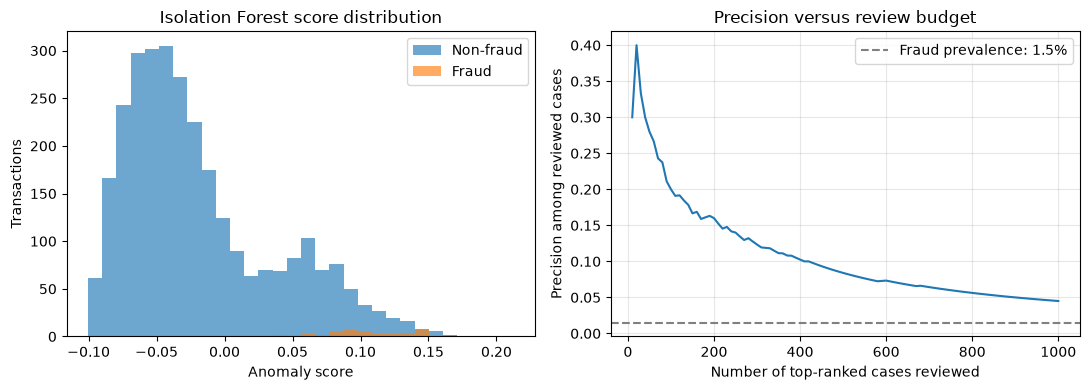

In [5]:
hits = ranked["fraud_label"].to_numpy()

k_values = np.arange(
    10,
    min(1000, len(ranked)) + 1,
    10,
)

precision_at_k = [
    hits[:k].mean()
    for k in k_values
]

# Shared bin boundaries make the histograms comparable.
bins = np.histogram_bin_edges(anomaly_score, bins=30)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(
    anomaly_score[y_test.to_numpy() == 0],
    bins=bins,
    alpha=0.65,
    label="Non-fraud",
)

axes[0].hist(
    anomaly_score[y_test.to_numpy() == 1],
    bins=bins,
    alpha=0.65,
    label="Fraud",
)

axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Isolation Forest score distribution")
axes[0].legend()

axes[1].plot(k_values, precision_at_k)

axes[1].axhline(
    prevalence,
    linestyle="--",
    color="gray",
    label=f"Fraud prevalence: {prevalence:.1%}",
)

axes[1].set_xlabel("Number of top-ranked cases reviewed")
axes[1].set_ylabel("Precision among reviewed cases")
axes[1].set_title("Precision versus review budget")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
rng = np.random.default_rng(42)

cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

display(cancer.head())

X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore",
)

y_c = (cancer["diagnosis"] == "M").astype(int).to_numpy()

X_dev, Xc_test, y_dev, yc_test = train_test_split(
    X_c,
    y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c,
)

X_pool, X_val, y_pool, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=7,
    stratify=y_dev,
)

X_pool = X_pool.reset_index(drop=True)
y_pool = np.asarray(y_pool)

print("Pool:", len(X_pool))
print("Validation:", len(X_val))
print("Sealed test:", len(Xc_test))
print("Labels: 0 = benign, 1 = malignant")


def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ])

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Pool: 319
Validation: 107
Sealed test: 143
Labels: 0 = benign, 1 = malignant


In [7]:
y_partial = y_pool.copy()
y_partial[rng.random(len(y_partial)) < 0.70] = -1

visible = y_partial != -1
labels_kept = int(visible.sum())

print("Labels kept:", labels_kept, "of", len(y_partial))
print("Labels hidden:", int((~visible).sum()))

# Baseline: learn only from genuinely labeled rows.
limited_model = make_model()

limited_model.fit(
    X_pool.loc[visible],
    y_partial[visible],
)

# Self-training: use the entire pool, with hidden labels marked -1.
semi = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        SelfTrainingClassifier(
            LogisticRegression(max_iter=2000),
            threshold=0.90,
        ),
    ),
])

semi.fit(X_pool, y_partial)

self_training_validation = pd.DataFrame([
    {
        "Method": "Visible-label baseline",
        "True labels": labels_kept,
        "Validation accuracy": accuracy_score(
            y_val,
            limited_model.predict(X_val),
        ),
    },
    {
        "Method": "Self-training, threshold=0.90",
        "True labels": labels_kept,
        "Validation accuracy": accuracy_score(
            y_val,
            semi.predict(X_val),
        ),
    },
])

display(self_training_validation.round(4))

transduced = semi.named_steps["model"].transduction_

pseudo_count = int(
    ((y_partial == -1) & (transduced != -1)).sum()
)

print("Pseudo-labels added:", pseudo_count)
print("Rows still unlabeled:", int((transduced == -1).sum()))

Labels kept: 89 of 319
Labels hidden: 230


,Method,True labels,Validation accuracy
0,Visible-label baseline,89,0.9720
1,"Self-training, threshold=0.90",89,0.9626


Pseudo-labels added: 201
Rows still unlabeled: 29


In [8]:
def run_query_experiment(
    labels_per_class,
    initial_rng,
    random_seed=123,
    rounds=8,
    query_batch=15,
):
    class0 = np.where(y_pool == 0)[0]
    class1 = np.where(y_pool == 1)[0]

    initial = np.concatenate([
        initial_rng.choice(
            class0,
            labels_per_class,
            replace=False,
        ),
        initial_rng.choice(
            class1,
            labels_per_class,
            replace=False,
        ),
    ])

    active_labeled = set(initial.tolist())
    random_labeled = set(initial.tolist())
    rng_random = np.random.default_rng(random_seed)

    rows = []

    for round_no in range(rounds):
        active_idx = sorted(active_labeled)
        random_idx = sorted(random_labeled)

        active_model = make_model().fit(
            X_pool.iloc[active_idx],
            y_pool[active_idx],
        )

        random_model = make_model().fit(
            X_pool.iloc[random_idx],
            y_pool[random_idx],
        )

        rows.append({
            "Round": round_no + 1,
            "Labels": len(active_idx),
            "Uncertainty validation accuracy": accuracy_score(
                y_val,
                active_model.predict(X_val),
            ),
            "Random validation accuracy": accuracy_score(
                y_val,
                random_model.predict(X_val),
            ),
        })

        if round_no == rounds - 1:
            break

        active_unlabeled = np.array([
            i for i in range(len(X_pool))
            if i not in active_labeled
        ])

        distances_from_half = np.abs(
            active_model.predict_proba(
                X_pool.iloc[active_unlabeled]
            )[:, 1] - 0.5
        )

        query_indices = active_unlabeled[
            np.argsort(distances_from_half)[:query_batch]
        ]

        active_labeled.update(query_indices.tolist())

        random_unlabeled = np.array([
            i for i in range(len(X_pool))
            if i not in random_labeled
        ])

        random_queries = rng_random.choice(
            random_unlabeled,
            size=query_batch,
            replace=False,
        )

        random_labeled.update(random_queries.tolist())

    return {
        "history": pd.DataFrame(rows),
        "active_model": active_model,
        "random_model": random_model,
        "final_labels": len(active_labeled),
    }

In [9]:
# The main experiment continues the RNG used for masking,
# following the lab's sequence.
experiment_40 = run_query_experiment(
    labels_per_class=20,
    initial_rng=rng,
)

# Separate reproducible starting sample for the extra experiment.
experiment_20 = run_query_experiment(
    labels_per_class=10,
    initial_rng=np.random.default_rng(42),
)

print("STARTING WITH 40 LABELS: 20 PER CLASS")
display(experiment_40["history"].round(4))

print("\nSTARTING WITH 20 LABELS: 10 PER CLASS")
display(experiment_20["history"].round(4))

STARTING WITH 40 LABELS: 20 PER CLASS


,Round,Labels,Uncertainty validation accuracy,Random validation accuracy
0,1,40,0.9439,0.9439
1,2,55,0.9252,0.9533
2,3,70,0.9813,0.9626
3,4,85,0.9533,0.9626
4,5,100,0.9533,0.9533
5,6,115,0.9533,0.9533
6,7,130,0.9533,0.9626
7,8,145,0.9533,0.9626



STARTING WITH 20 LABELS: 10 PER CLASS


,Round,Labels,Uncertainty validation accuracy,Random validation accuracy
0,1,20,0.9346,0.9346
1,2,35,0.9439,0.9439
2,3,50,0.9626,0.9626
3,4,65,0.9533,0.9533
4,5,80,0.9533,0.9626
5,6,95,0.9533,0.9439
6,7,110,0.9533,0.9533
7,8,125,0.9533,0.9439


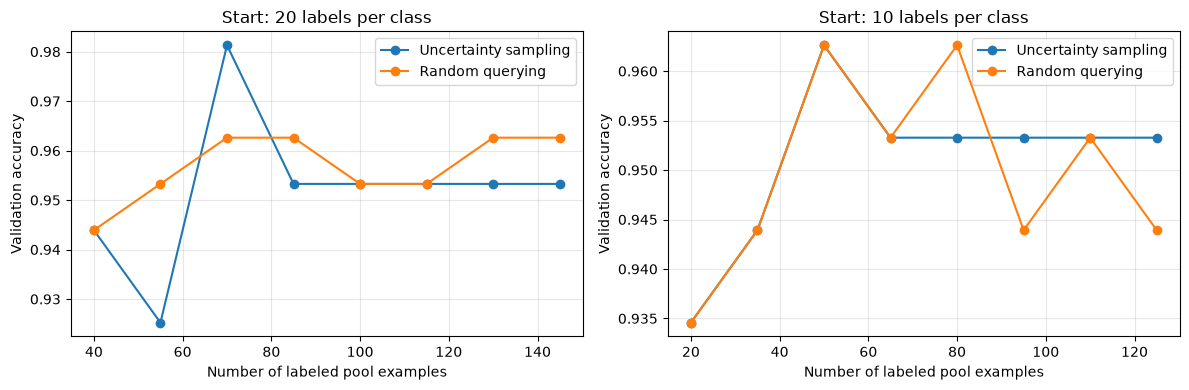

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

experiments = [
    (axes[0], experiment_40, "Start: 20 labels per class"),
    (axes[1], experiment_20, "Start: 10 labels per class"),
]

for ax, experiment, title in experiments:
    history = experiment["history"]

    ax.plot(
        history["Labels"],
        history["Uncertainty validation accuracy"],
        marker="o",
        label="Uncertainty sampling",
    )

    ax.plot(
        history["Labels"],
        history["Random validation accuracy"],
        marker="o",
        label="Random querying",
    )

    ax.set_xlabel("Number of labeled pool examples")
    ax.set_ylabel("Validation accuracy")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
final_rows = []

models_to_evaluate = [
    (
        "Visible-label baseline",
        labels_kept,
        limited_model,
    ),
    (
        "Self-training",
        labels_kept,
        semi,
    ),
    (
        "Uncertainty: start 40",
        experiment_40["final_labels"],
        experiment_40["active_model"],
    ),
    (
        "Random: start 40",
        experiment_40["final_labels"],
        experiment_40["random_model"],
    ),
    (
        "Uncertainty: start 20",
        experiment_20["final_labels"],
        experiment_20["active_model"],
    ),
    (
        "Random: start 20",
        experiment_20["final_labels"],
        experiment_20["random_model"],
    ),
]

for name, true_labels, model in models_to_evaluate:
    final_rows.append({
        "Method": name,
        "True pool labels used": true_labels,
        "Test accuracy": accuracy_score(
            yc_test,
            model.predict(Xc_test),
        ),
    })

final_test_results = pd.DataFrame(final_rows)

display(final_test_results.round(4))

,Method,True pool labels used,Test accuracy
0,Visible-label baseline,89,0.965
1,Self-training,89,0.958
2,Uncertainty: start 40,145,0.972
3,Random: start 40,145,0.972
4,Uncertainty: start 20,125,0.972
5,Random: start 20,125,0.951


In [12]:
print("PART A: FRAUD RANKING METRICS")
print(fraud_metrics.round(4).to_string(index=False))

print("\nPART A: REVIEW BUDGET COMPARISON")
print(budget_results.round(4).to_string(index=False))

print("\nPART B: SELF-TRAINING VALIDATION")
print(self_training_validation.round(4).to_string(index=False))

print("\nSelf-training pseudo-labels added:", pseudo_count)

print("\nACTIVE LEARNING: START WITH 40 LABELS")
print(
    experiment_40["history"]
    .round(4)
    .to_string(index=False)
)

print("\nACTIVE LEARNING: START WITH 20 LABELS")
print(
    experiment_20["history"]
    .round(4)
    .to_string(index=False)
)

print("\nFINAL TEST RESULTS")
print(final_test_results.round(4).to_string(index=False))

PART A: FRAUD RANKING METRICS
                        Metric   Value
         Test fraud prevalence  0.0150
                       ROC AUC  0.9518
             Average precision  0.2249
Average precision / prevalence 14.9939

PART A: REVIEW BUDGET COMPARISON
 Review budget  Fraud found  Non-fraud alerts  Precision  Recall  Precision / prevalence
            50           14                36     0.2800  0.3111                 18.6667
           100           20                80     0.2000  0.4444                 13.3333
           300           37               263     0.1233  0.8222                  8.2222

PART B: SELF-TRAINING VALIDATION
                       Method  True labels  Validation accuracy
       Visible-label baseline           89               0.9720
Self-training, threshold=0.90           89               0.9626

Self-training pseudo-labels added: 201

ACTIVE LEARNING: START WITH 40 LABELS
 Round  Labels  Uncertainty validation accuracy  Random validation accuracy
    

# Lab 5: Anomaly Detection and Limited Labels

## Part A: Isolation Forest Fraud Ranking

Isolation Forest was fitted using transaction features without passing the fraud labels to the model. The held-back test labels were used only to evaluate the anomaly ranking. Higher anomaly scores represented more unusual transactions, rather than confirmed fraud.

### Ranking Performance

| Metric | Result |
|---|---:|
| Test fraud prevalence | 1.50% |
| ROC AUC | 0.9518 |
| Average precision | 0.2249 |
| Average precision divided by prevalence | Approximately 15 times |

The ROC AUC indicates strong overall ranking performance. Average precision was substantially above the 1.5% prevalence baseline, showing that fraud cases were concentrated toward the top of the ranking.

However, the score distributions overlap. Some legitimate transactions received high anomaly scores, so a strong ROC AUC did not eliminate false alerts.

### Review Budget Comparison

| Transactions reviewed | Fraud found | Non-fraud alerts | Precision | Recall |
|---|---:|---:|---:|---:|
| 50 | 14 | 36 | 28.00% | 31.11% |
| 100 | 20 | 80 | 20.00% | 44.44% |
| 300 | 37 | 263 | 12.33% | 82.22% |

Reviewing the top 50 transactions produced the highest precision among these budgets: 28%. Reviewing 300 transactions found more fraud cases, increasing recall to 82.22%, but precision decreased to 12.33%.

Increasing the budget from 50 to 300 required 250 additional reviews to identify 23 additional fraud cases. Therefore, a larger review budget improves fraud coverage but also increases the investigation workload and number of false alerts.

The precision curve generally decreased as the review budget increased. The most suspicious transactions were concentrated near the top, while lower-ranked cases contained a larger proportion of legitimate transactions.

For a team with capacity to review 100 transactions, the relevant result is **20 fraud cases and 80 non-fraud alerts**, giving 20% precision. The review budget should reflect available investigation resources and the consequences of missed fraud and false alerts.

## Part B: Self-training with Limited Labels

Approximately 70% of the pool labels were hidden using the value -1. This left **89 genuine labels** available for training.

The visible-label baseline used only these labeled rows. Self-training also used the unlabeled pool and added predictions when confidence exceeded the 0.90 threshold.

### Self-training Results

| Method | Genuine labels used | Validation accuracy | Test accuracy |
|---|---:|---:|---:|
| Visible-label baseline | 89 | 97.20% | 96.5% |
| Self-training | 89 | 96.26% | 95.8% |

Self-training added **201 pseudo-labels**, but it did not improve accuracy in this experiment. Both validation and test accuracy were lower than those of the visible-label baseline.

One possible explanation is that incorrect confident predictions introduced errors into subsequent training. Confidence alone does not guarantee that a pseudo-label is correct. The results show that adding unlabeled examples through self-training does not automatically improve performance.

## Part C: Active Learning versus Random Querying

Uncertainty sampling selected pool examples whose predicted probability was closest to 0.5. Random querying selected examples randomly.

Both policies started with the same labeled examples within each experiment and acquired 15 additional genuine labels per round. They used the same fixed validation and test sets, allowing comparison at equal label budgets.

### Starting with 20 Labels per Class

Both policies began with **40 labels** and finished with **145 labels**.

| Policy | Final label budget | Final validation accuracy | Final test accuracy |
|---|---:|---:|---:|
| Uncertainty sampling | 145 | 95.33% | 97.2% |
| Random querying | 145 | 96.26% | 97.2% |

Uncertainty sampling reached a validation accuracy of 98.13% at 70 labels, but this improvement did not persist. At the final round, random querying had slightly higher validation accuracy, while both policies achieved the same reported test accuracy.

Therefore, uncertainty sampling did not show a consistent advantage over random querying with this starting budget. The changing validation scores also show that acquiring more labels does not guarantee an accuracy increase at every round.

### Try It Yourself: Starting with Ten Labels per Class

Both policies began with **20 labels** and finished with **125 labels**.

| Policy | Final label budget | Final validation accuracy | Final test accuracy |
|---|---:|---:|---:|
| Uncertainty sampling | 125 | 95.33% | 97.2% |
| Random querying | 125 | 94.39% | 95.1% |

With this smaller starting budget, uncertainty sampling achieved higher final validation and test accuracy than random querying. Its test accuracy was higher by **2.1 percentage points**, based on the displayed results.

The uncertainty policy reached the same reported test accuracy of 97.2% using 125 labels as it did using 145 labels in the other experiment. However, the experiments used different initial samples, so this alone does not establish that the smaller starting budget is generally better.

These findings come from one run for each starting budget. Repeating the experiments with several random seeds would provide stronger evidence about whether uncertainty sampling consistently improves label efficiency.

## Overall Comparison

All breast-cancer methods were evaluated on the same held-out test set. However, self-training and the query experiments used different genuine-label budgets, so their accuracy differences cannot be attributed only to the learning method.

Self-training did not improve on its visible-label baseline. Active learning matched random querying in the 40-label starting experiment and outperformed it in the 20-label starting experiment. The benefit of uncertainty sampling therefore depended on the experimental setting.

## Check Your Understanding

### 1. Why is an anomaly score not automatically a probability of fraud, failure, or error?

An anomaly score measures how unusual an observation is relative to the model's learned reference pattern. Isolation Forest learns isolation patterns without using fraud labels, so its scores are not calibrated probabilities of fraud. An unusual transaction may be legitimate, while fraud may sometimes resemble normal behavior.

### 2. How does a fixed review capacity turn anomaly detection into a ranking problem?

If investigators can review only a fixed number of transactions, the model must place the most useful cases near the top of its ranking. The team reviews the top k cases, and precision at k measures how many of those reviews identify actual fraud. This connects model evaluation directly to operational capacity.

### 3. What is the difference between outlier detection and novelty detection?

Outlier detection identifies unusual observations when the training sample itself may contain anomalies.

Novelty detection learns from a reference sample intended to represent normal behavior and then identifies unusual future observations. The key difference is whether anomalies may already be present in the training data.